# 02 - Training
Fine-tuning backbone pretrained (timm) dengan PyTorch.

In [1]:
import os, sys, subprocess
REPO_URL = "https://github.com/azizahadilaa/document-image-classification-kaggle.git" 
REPO_DIR = "/kaggle/working/document-image-classification-kaggle"
if not os.path.exists(REPO_DIR):
    subprocess.run(["git", "clone", REPO_URL, REPO_DIR], check=True)
sys.path.append(REPO_DIR)

import pandas as pd, numpy as np, torch
from scripts.utils import set_seed, find_data_dir
set_seed(42)
DATA_DIR = find_data_dir()
CACHE_DIR = "/kaggle/temp/cache"
IMG_SIZE = 320
train_df = pd.read_csv(f"{DATA_DIR}/train.csv")
test_df = pd.read_csv(f"{DATA_DIR}/test.csv")
print(DATA_DIR, train_df.shape, test_df.shape)

Cloning into '/kaggle/working/document-image-classification-kaggle'...


/kaggle/input/competitions/document-image-classification-sd234504 (32003, 4) (7994, 2)


In [2]:
from scripts.preprocess import cache_images
cache_images(train_df, DATA_DIR, CACHE_DIR, IMG_SIZE)   # dilewati otomatis jika sudah ada
cache_images(test_df, DATA_DIR, CACHE_DIR, IMG_SIZE)

 27%|██▋       | 8746/32003 [00:21<00:58, 395.68it/s]/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Corrupt EXIF data.  Expecting to read 2 bytes but only got 0. 
  warnings.warn(str(msg))
100%|██████████| 32003/32003 [01:19<00:00, 401.02it/s]


Selesai: 32002 berhasil, 1 gagal


100%|██████████| 7994/7994 [00:19<00:00, 405.23it/s]

Selesai: 7994 berhasil, 0 gagal


## Konfigurasi & DataLoader (split stratified 90/10)

In [4]:
from sklearn.model_selection import train_test_split
from scripts.dataset import make_loader
CFG = dict(model="efficientnet_b3", epochs=8, lr=3e-4, batch_size=32, label_smoothing=0.1, weight_decay=0.05)
tr_df, va_df = train_test_split(train_df, test_size=0.1, stratify=train_df["label"], random_state=42)
train_loader = make_loader(tr_df, CACHE_DIR, IMG_SIZE, CFG["batch_size"], train=True)
val_loader = make_loader(va_df, CACHE_DIR, IMG_SIZE, CFG["batch_size"], train=False)
print(len(tr_df), len(va_df))

28802 3201


## Model & training

In [5]:
from scripts.model import build_model
from scripts.train import fit
device = "cuda"
set_seed(11)
model = build_model(CFG["model"], num_classes=train_df["label"].nunique(), drop_path_rate=0.2)
history = fit(model, train_loader, val_loader, device, ckpt_dir="/kaggle/working/checkpoint",
                epochs=CFG["epochs"], lr=CFG["lr"], weight_decay=CFG["weight_decay"],
                label_smoothing=CFG["label_smoothing"], tag=CFG["model"])

model.safetensors: reconstructing file:   0%|          |  0.00B / 49.3MB            

model.safetensors: downloading bytes:           |  0.00B            

  0%|          | 0/900 [00:00<?, ?it/s]/kaggle/working/document-image-classification-kaggle/scripts/train.py:49: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


Epoch 1/8 | train 1.9102/0.5221 | val 1.2351/0.7610
  -> checkpoint terbaik disimpan (val acc 0.7610)


Epoch 2/8 | train 1.1860/0.7792 | val 1.0523/0.8219
  -> checkpoint terbaik disimpan (val acc 0.8219)


Epoch 3/8 | train 1.0058/0.8459 | val 0.9733/0.8557
  -> checkpoint terbaik disimpan (val acc 0.8557)


Epoch 4/8 | train 0.8942/0.8856 | val 0.9434/0.8663
  -> checkpoint terbaik disimpan (val acc 0.8663)


Epoch 5/8 | train 0.8051/0.9194 | val 0.9257/0.8697
  -> checkpoint terbaik disimpan (val acc 0.8697)


Epoch 6/8 | train 0.7346/0.9476 | val 0.9241/0.8729
  -> checkpoint terbaik disimpan (val acc 0.8729)


Epoch 7/8 | train 0.6902/0.9656 | val 0.9183/0.8779
  -> checkpoint terbaik disimpan (val acc 0.8779)


Epoch 8/8 | train 0.6745/0.9718 | val 0.9160/0.8763


## Kurva training & confusion matrix

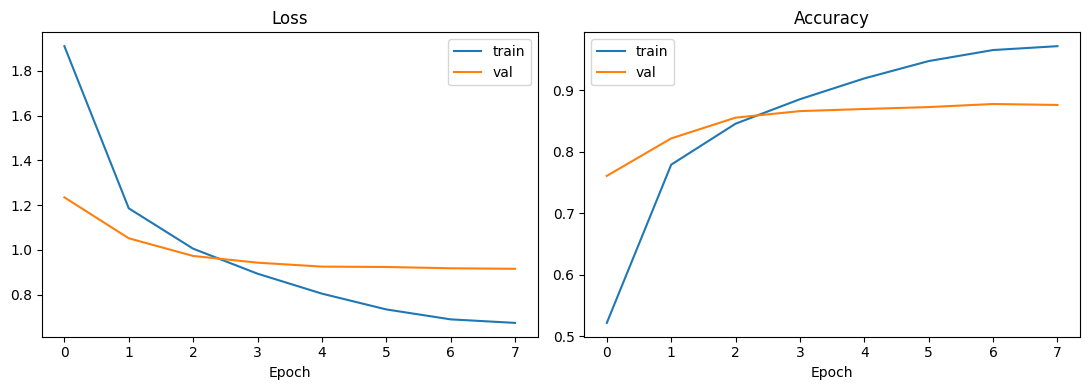

Best val acc: 0.8778506716651047


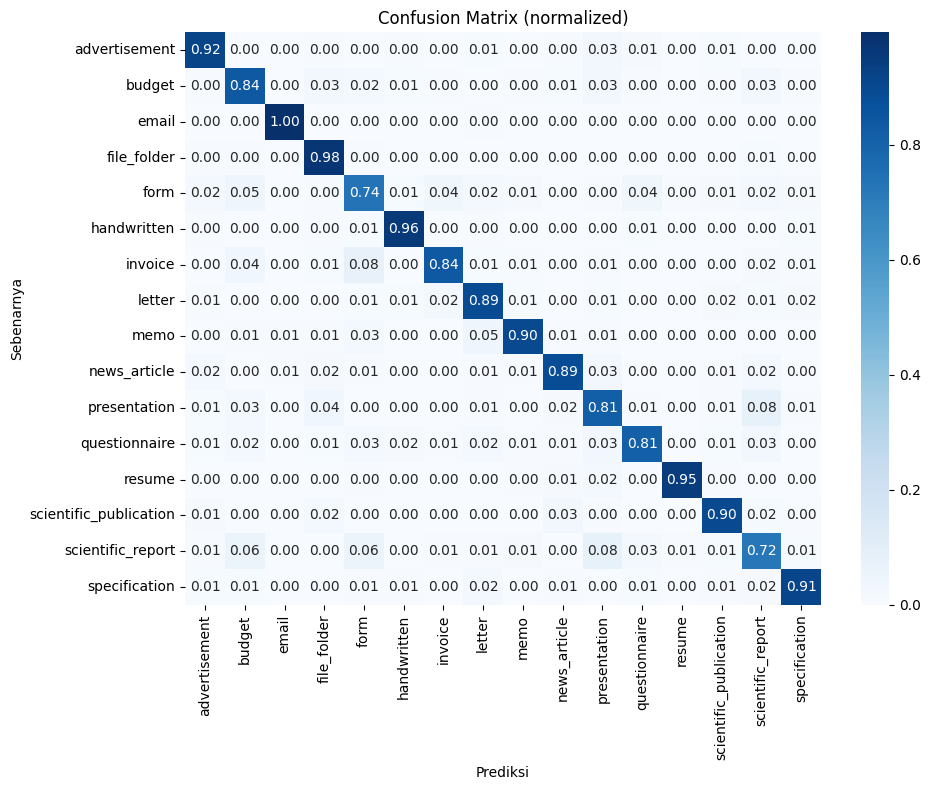

                        precision    recall  f1-score   support

         advertisement      0.894     0.920     0.907       201
                budget      0.800     0.836     0.818       201
                 email      0.990     0.995     0.993       201
           file_folder      0.872     0.975     0.921       202
                  form      0.751     0.736     0.744       201
           handwritten      0.946     0.956     0.951       203
               invoice      0.917     0.838     0.876       198
                letter      0.850     0.893     0.871       197
                  memo      0.932     0.899     0.916       199
          news_article      0.902     0.888     0.895       197
          presentation      0.761     0.814     0.786       199
         questionnaire      0.878     0.810     0.843       195
                resume      0.990     0.946     0.967       203
scientific_publication      0.916     0.898     0.907       206
     scientific_report      0.735     0

In [6]:
from scripts.utils import plot_history, plot_confusion_matrix
from scripts.train import evaluate
import torch.nn as nn
fig_dir = f"{REPO_DIR}/reports/figures"; os.makedirs(fig_dir, exist_ok=True)
plot_history(history, f"{fig_dir}/training_curve.png")
model.load_state_dict(torch.load(f"/kaggle/working/checkpoint/{CFG['model']}_best.pt"))
_, acc, preds, gts = evaluate(model, val_loader, nn.CrossEntropyLoss(), device)
names = train_df.drop_duplicates("label").sort_values("label")["class_name"].tolist()
print("Best val acc:", acc)
plot_confusion_matrix(gts, preds, names, f"{fig_dir}/confusion_matrix.png")
from sklearn.metrics import classification_report
print(classification_report(gts, preds, target_names=names, digits=3))